In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import entropy, skew, kurtosis

In [22]:
pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (10, 6)
sns.set(style="whitegrid")

In [23]:
df = pd.read_csv("api_data_aadhar_enrolment_0_500000.csv") 
df.head()

,date,state,district,pincode,age_0_5,age_5_17,age_18_greater
0,02-03-2025,Meghalaya,East Khasi Hills,793121,11,61,37
1,09-03-2025,Karnataka,Bengaluru Urban,560043,14,33,39
2,09-03-2025,Uttar Pradesh,Kanpur Nagar,208001,29,82,12
3,09-03-2025,Uttar Pradesh,Aligarh,202133,62,29,15
4,09-03-2025,Karnataka,Bengaluru Urban,560016,14,16,21


In [24]:
print("Rows, Columns:", df.shape)

Rows, Columns: (500000, 7)


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   date            500000 non-null  object
 1   state           500000 non-null  object
 2   district        500000 non-null  object
 3   pincode         500000 non-null  int64 
 4   age_0_5         500000 non-null  int64 
 5   age_5_17        500000 non-null  int64 
 6   age_18_greater  500000 non-null  int64 
dtypes: int64(4), object(3)
memory usage: 26.7+ MB


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   date            500000 non-null  object
 1   state           500000 non-null  object
 2   district        500000 non-null  object
 3   pincode         500000 non-null  int64 
 4   age_0_5         500000 non-null  int64 
 5   age_5_17        500000 non-null  int64 
 6   age_18_greater  500000 non-null  int64 
dtypes: int64(4), object(3)
memory usage: 26.7+ MB


In [26]:
df.describe(include="all")

,date,state,district,pincode,age_0_5,age_5_17,age_18_greater
count,500000,500000,500000,500000.000000,500000.000000,500000.000000,500000.000000
unique,56,54,971,NaN,NaN,NaN,NaN
top,17-10-2025,Uttar Pradesh,North 24 Parganas,NaN,NaN,NaN,NaN
freq,18361,57240,3392,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,519204.051054,4.040812,2.315682,0.245558
std,NaN,NaN,NaN,206793.322085,24.417921,20.191196,4.438557
min,NaN,NaN,NaN,100000.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,NaN,362229.000000,1.000000,0.000000,0.000000
50%,NaN,NaN,NaN,517131.000000,2.000000,0.000000,0.000000
75%,NaN,NaN,NaN,712139.000000,3.000000,1.000000,0.000000


In [28]:
# Remove duplicates
df = df.drop_duplicates()

# Drop rows with missing critical fields
df = df.dropna(subset=["date", "state", "district"])

# Convert date column
df["date"] = pd.to_datetime(df["date"], errors="coerce", dayfirst=True)

# Convert numeric columns
age_cols = ["age_0_5", "age_5_17", "age_18_greater"]
for col in age_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Drop rows where all age values are missing
df = df.dropna(subset=age_cols, how="all")

df.head()


,date,state,district,pincode,age_0_5,age_5_17,age_18_greater
0,2025-03-02,Meghalaya,East Khasi Hills,793121,11,61,37
1,2025-03-09,Karnataka,Bengaluru Urban,560043,14,33,39
2,2025-03-09,Uttar Pradesh,Kanpur Nagar,208001,29,82,12
3,2025-03-09,Uttar Pradesh,Aligarh,202133,62,29,15
4,2025-03-09,Karnataka,Bengaluru Urban,560016,14,16,21


In [29]:
# Total enrollments
df["total_enrollments"] = df[age_cols].sum(axis=1)

# Extract time features
df["month"] = df["date"].dt.to_period("M")
df["year"] = df["date"].dt.year

df.head()


,date,state,district,pincode,age_0_5,age_5_17,age_18_greater,total_enrollments,month,year
0,2025-03-02,Meghalaya,East Khasi Hills,793121,11,61,37,109,2025-03,2025
1,2025-03-09,Karnataka,Bengaluru Urban,560043,14,33,39,86,2025-03,2025
2,2025-03-09,Uttar Pradesh,Kanpur Nagar,208001,29,82,12,123,2025-03,2025
3,2025-03-09,Uttar Pradesh,Aligarh,202133,62,29,15,106,2025-03,2025
4,2025-03-09,Karnataka,Bengaluru Urban,560016,14,16,21,51,2025-03,2025


In [30]:
state_enrollment = (
    df.groupby("state")["total_enrollments"]
    .sum()
    .sort_values(ascending=False)
)

state_enrollment.head(10)


state
Uttar Pradesh     663768
Bihar             387515
Madhya Pradesh    276085
Maharashtra       220535
West Bengal       218621
Rajasthan         204529
Gujarat           192525
Assam             166398
Karnataka         120709
Tamil Nadu        103942
Name: total_enrollments, dtype: int64

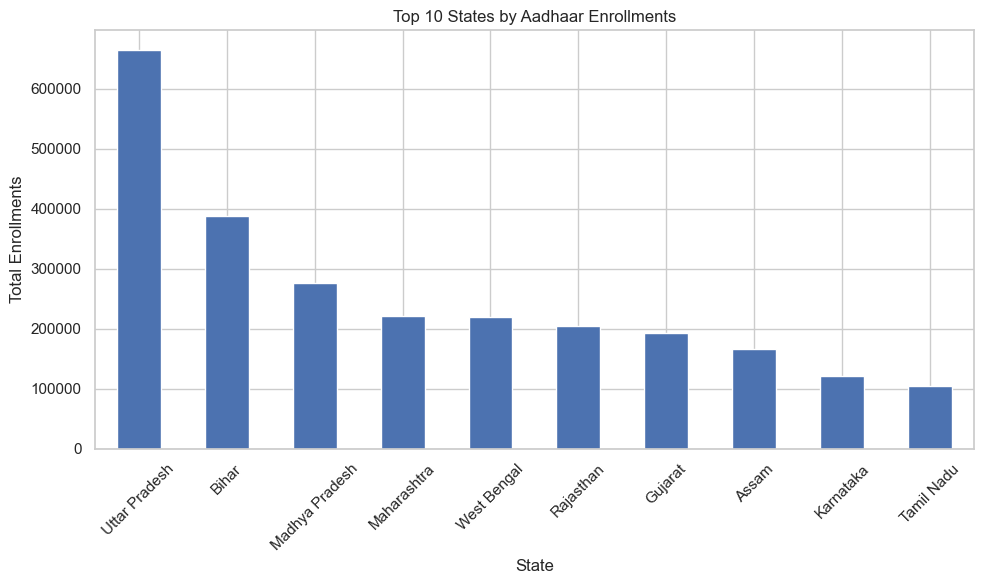

In [31]:
state_enrollment.head(10).plot(kind="bar")
plt.title("Top 10 States by Aadhaar Enrollments")
plt.xlabel("State")
plt.ylabel("Total Enrollments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [32]:
district_enrollment = (
    df.groupby("district")["total_enrollments"]
    .sum()
    .sort_values(ascending=False)
)

district_enrollment.head(10)


district
Sitamarhi           34155
Bahraich            32384
Thane               29262
East Khasi Hills    25845
Bengaluru Urban     23074
Sitapur             22962
West Champaran      20842
Agra                20730
Bengaluru           20418
Muzaffarpur         20412
Name: total_enrollments, dtype: int64

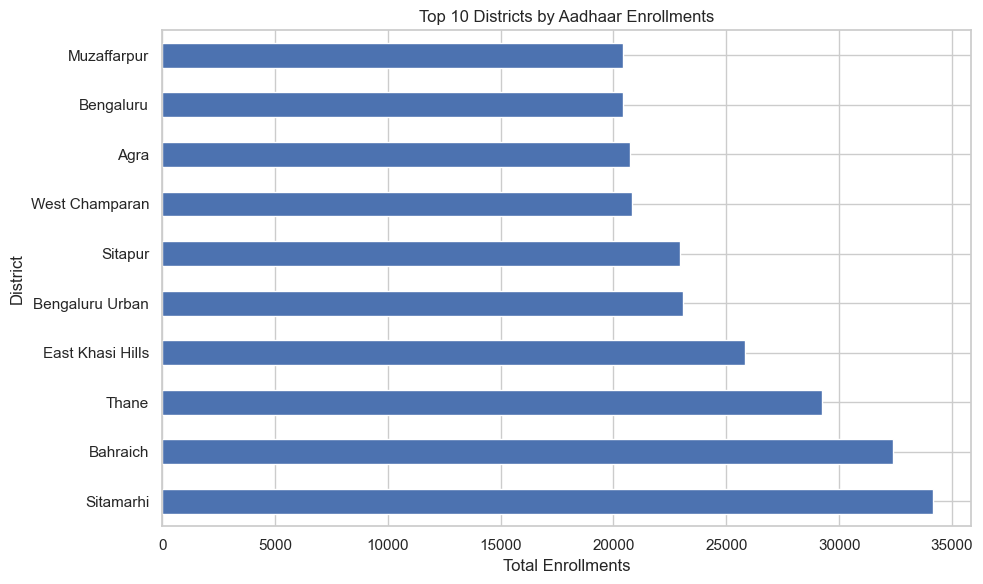

In [33]:
district_enrollment.head(10).plot(kind="barh")
plt.title("Top 10 Districts by Aadhaar Enrollments")
plt.xlabel("Total Enrollments")
plt.ylabel("District")
plt.tight_layout()
plt.show()


In [34]:
age_distribution = df[age_cols].sum()
age_distribution


age_0_5           2001557
age_5_17          1149853
age_18_greater     122345
dtype: int64

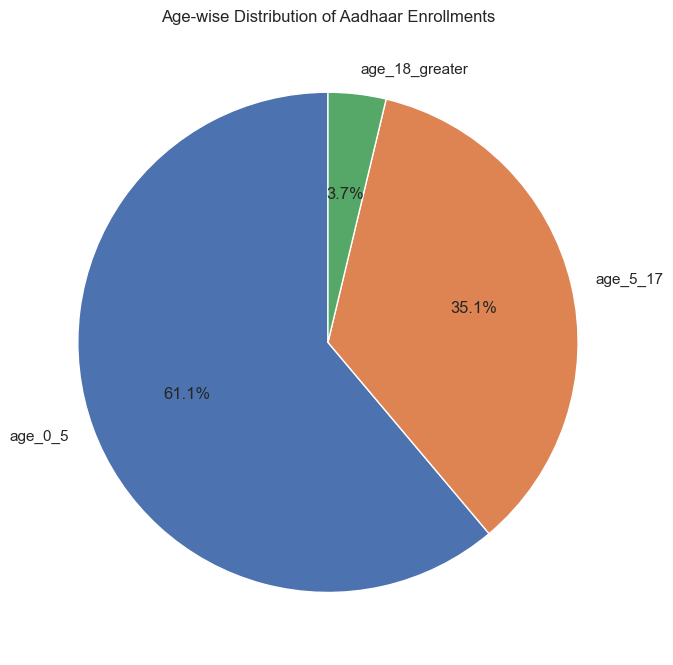

In [35]:
plt.figure(figsize=(7,7))
age_distribution.plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Age-wise Distribution of Aadhaar Enrollments")
plt.ylabel("")
plt.tight_layout()
plt.show()


In [36]:
monthly_trend = (
    df.groupby("month")["total_enrollments"]
    .sum()
    .sort_index()
)

monthly_trend.head()


month
2025-03     16582
2025-04    257438
2025-05    183616
2025-06    215734
2025-07    616868
Freq: M, Name: total_enrollments, dtype: int64

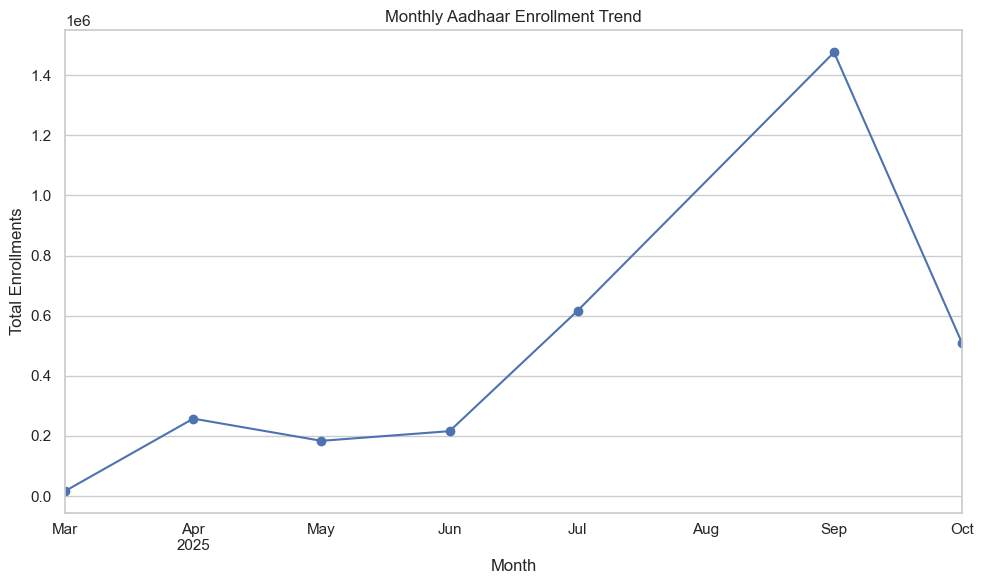

In [37]:
monthly_trend.plot(marker="o")
plt.title("Monthly Aadhaar Enrollment Trend")
plt.xlabel("Month")
plt.ylabel("Total Enrollments")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


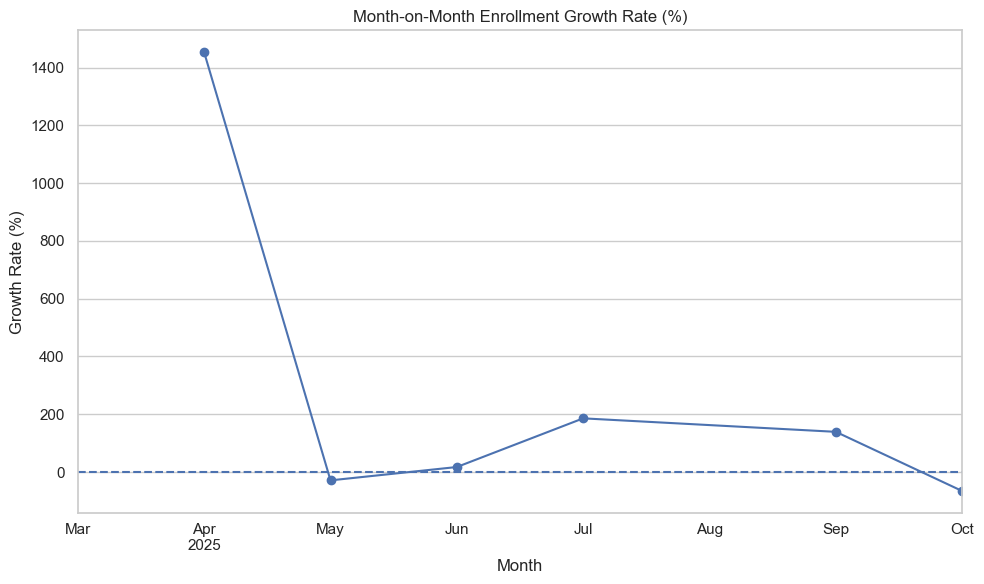

In [38]:
monthly_growth = monthly_trend.pct_change() * 100

monthly_growth.plot(marker="o")
plt.axhline(0, linestyle="--")
plt.title("Month-on-Month Enrollment Growth Rate (%)")
plt.xlabel("Month")
plt.ylabel("Growth Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


C:\Users\ASUS\AppData\Local\Temp\ipykernel_18736\4086723315.py:7: UserWarning: Glyph 10004 (\N{HEAVY CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Python310\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10004 (\N{HEAVY CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


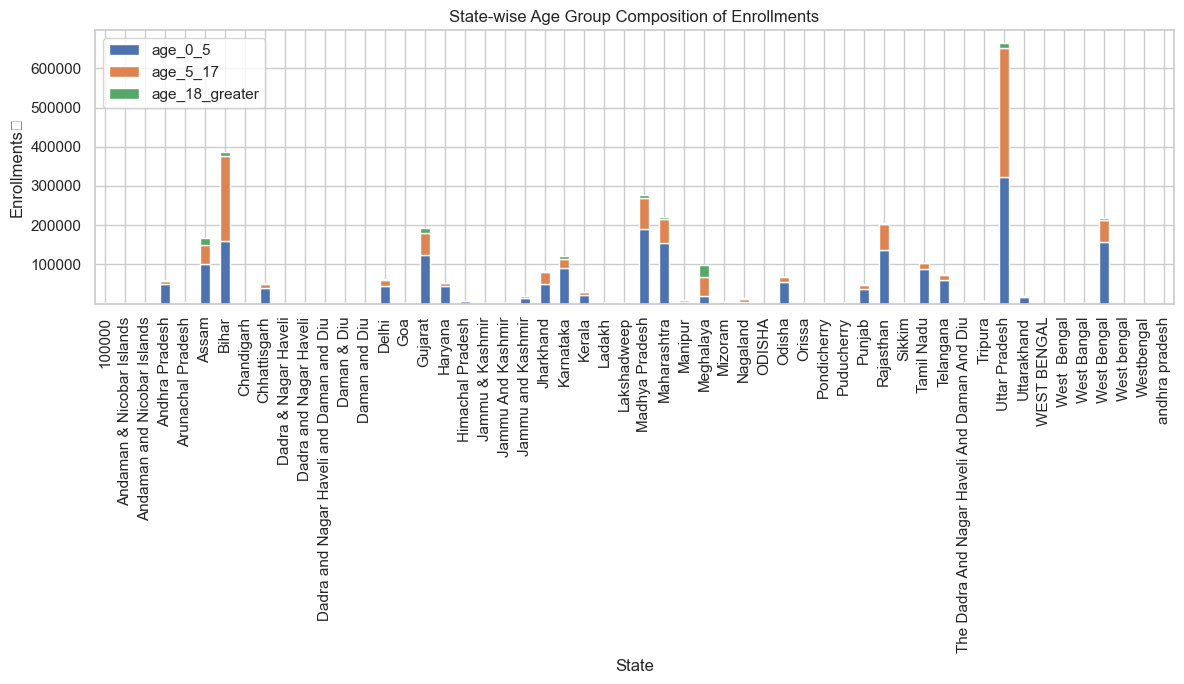

In [39]:
state_age = df.groupby("state")[age_cols].sum()

state_age.plot(kind="bar", stacked=True, figsize=(12,7))
plt.title("State-wise Age Group Composition of Enrollments")
plt.xlabel("State")
plt.ylabel("Enrollments✔")
plt.tight_layout()
plt.show()


In [40]:
state_stats = df.groupby("state")["total_enrollments"].agg(["mean", "std"])
state_stats["cv"] = state_stats["std"] / (state_stats["mean"] + 1)

top_cv_states = state_stats["cv"].sort_values(ascending=False).head(10)
top_cv_states


state
Manipur           7.605663
Haryana           6.413796
Maharashtra       6.260374
Punjab            6.135643
Uttarakhand       6.040849
Uttar Pradesh     6.023687
Delhi             5.469584
Gujarat           5.128637
Madhya Pradesh    4.804862
Rajasthan         4.764956
Name: cv, dtype: float64

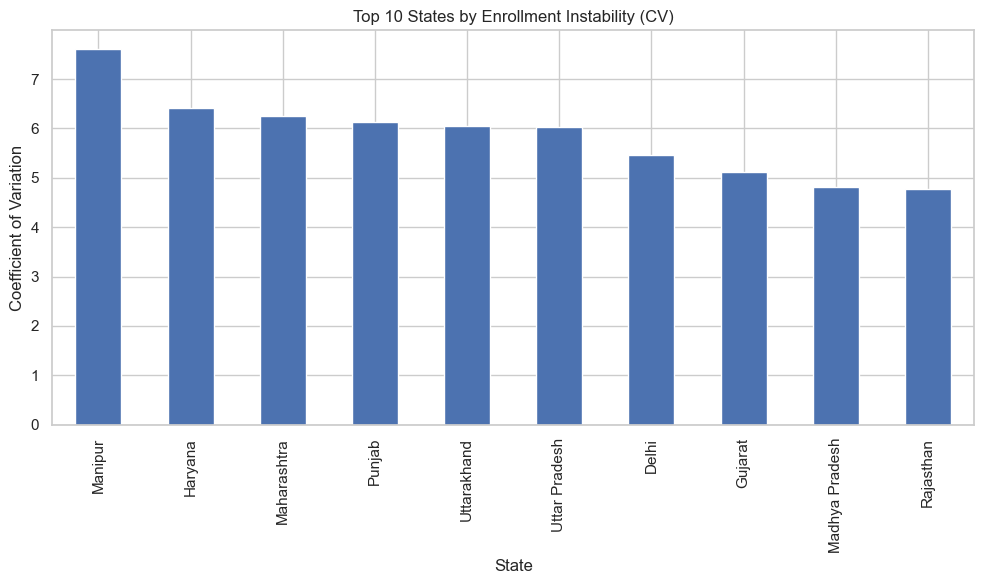

In [41]:
top_cv_states.plot(kind="bar")
plt.title("Top 10 States by Enrollment Instability (CV)")
plt.xlabel("State")
plt.ylabel("Coefficient of Variation")
plt.tight_layout()
plt.show()


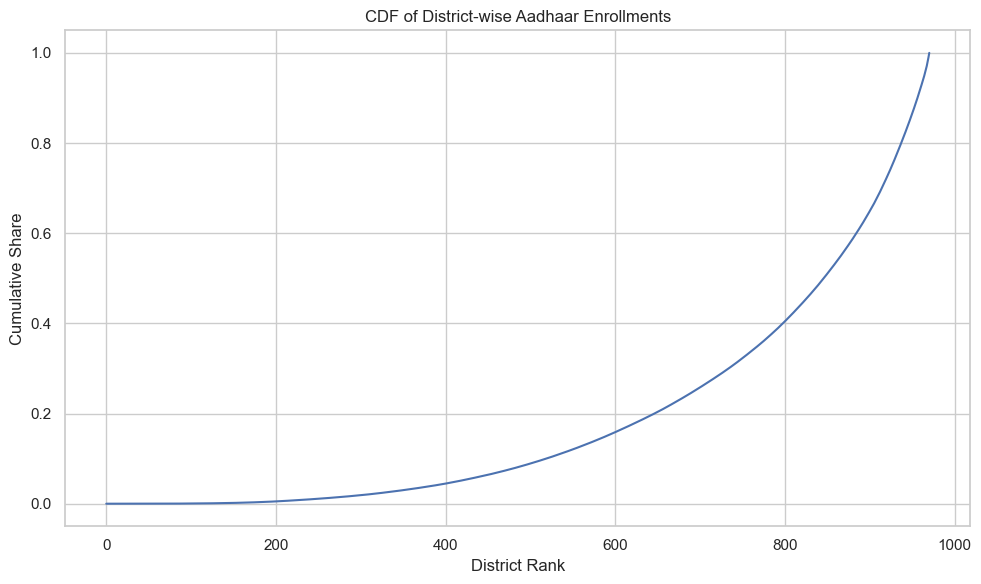

In [42]:
district_totals = district_enrollment.sort_values()
cdf = district_totals.cumsum() / district_totals.sum()

plt.plot(cdf.values)
plt.title("CDF of District-wise Aadhaar Enrollments")
plt.xlabel("District Rank")
plt.ylabel("Cumulative Share")
plt.tight_layout()
plt.show()


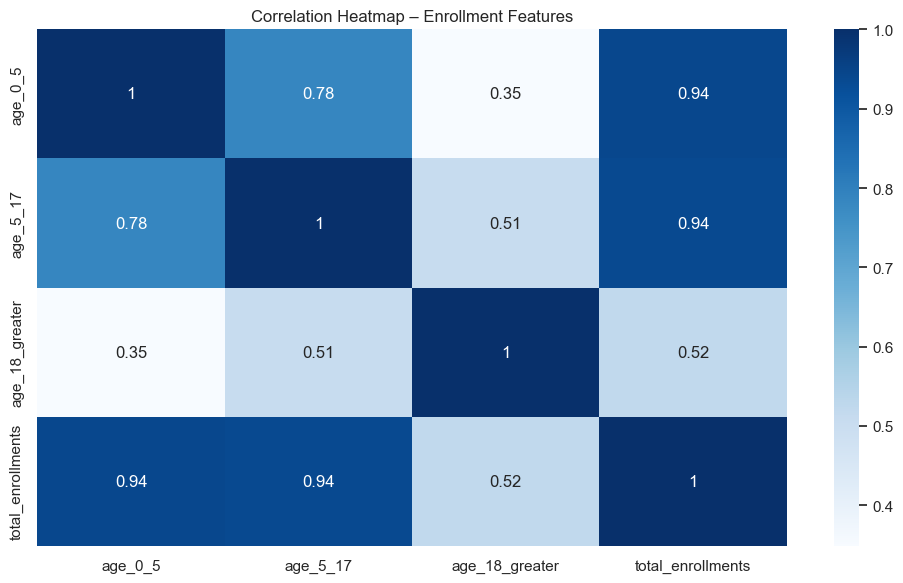

In [43]:
numeric_cols = df[age_cols + ["total_enrollments"]]
corr = numeric_cols.corr()

sns.heatmap(corr, annot=True, cmap="Blues")
plt.title("Correlation Heatmap – Enrollment Features")
plt.tight_layout()
plt.show()


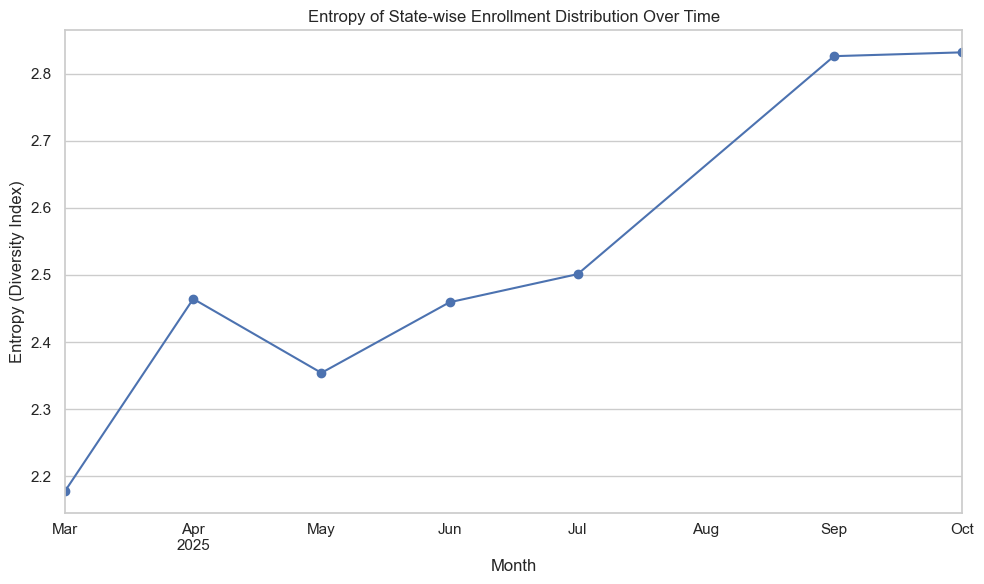

In [47]:
state_month_matrix = (
    df.groupby(["month", "state"])["total_enrollments"]
    .sum()
    .unstack(fill_value=0)
)

diversity = state_month_matrix.apply(lambda x: entropy(x + 1), axis=1)

diversity.plot(marker="o")
plt.title("Entropy of State-wise Enrollment Distribution Over Time")
plt.xlabel("Month")
plt.ylabel("Entropy (Diversity Index)")
plt.grid(True)
plt.tight_layout()
plt.show()
